In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("../datasets/spotify/spotify.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 114000
Columns: 20


In [4]:
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [5]:
print(df.columns.tolist())

['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  object 
 1   artists           113999 non-null  object 
 2   album_name        113999 non-null  object 
 3   track_name        113999 non-null  object 
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           11

In [7]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate track IDs:")
print(df["track_id"].duplicated().sum())

print("\nUnique artists:", df["artists"].nunique())
print("Unique albums:", df["album_name"].nunique())
print("Unique tracks:", df["track_name"].nunique())
print("Unique genres:", df["track_genre"].nunique())

Missing values:
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

Duplicate rows:
450

Duplicate track IDs:
24259

Unique artists: 31437
Unique albums: 46589
Unique tracks: 73608
Unique genres: 114


In [8]:
print("\nNumerical statistics:")
print(df.describe().round(2))


Numerical statistics:
       popularity  duration_ms  danceability     energy        key   loudness  \
count   114000.00    114000.00     114000.00  114000.00  114000.00  114000.00   
mean        33.24    228029.15          0.57       0.64       5.31      -8.26   
std         22.31    107297.71          0.17       0.25       3.56       5.03   
min          0.00         0.00          0.00       0.00       0.00     -49.53   
25%         17.00    174066.00          0.46       0.47       2.00     -10.01   
50%         35.00    212906.00          0.58       0.68       5.00      -7.00   
75%         50.00    261506.00          0.70       0.85       8.00      -5.00   
max        100.00   5237295.00          0.98       1.00      11.00       4.53   

            mode  speechiness  acousticness  instrumentalness   liveness  \
count  114000.00    114000.00     114000.00         114000.00  114000.00   
mean        0.64         0.08          0.31              0.16       0.21   
std         0.48   

In [9]:
print("\nExplicit content:")
print(df["explicit"].value_counts())

print("\nExplicit content percentage:")
print((df["explicit"].value_counts(normalize=True) * 100).round(2))


Explicit content:
explicit
False    104253
True       9747
Name: count, dtype: int64

Explicit content percentage:
explicit
False    91.45
True      8.55
Name: proportion, dtype: float64


In [10]:
df_clean = df.copy()

In [11]:
df_clean = df_clean.drop_duplicates()

print("Rows after removing duplicates:", len(df_clean))

Rows after removing duplicates: 113550


In [12]:
df_clean = df_clean.dropna(
    subset=["artists", "album_name", "track_name"]
)

print("Rows after removing missing values:", len(df_clean))

Rows after removing missing values: 113549


In [13]:
df_clean["duration_min"] = (
    df_clean["duration_ms"] / 60000
).round(2)

print(df_clean[["duration_ms", "duration_min"]].head())

   duration_ms  duration_min
0       230666          3.84
1       149610          2.49
2       210826          3.51
3       201933          3.37
4       198853          3.31


In [14]:
print("Final dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

Final dataset shape: (113549, 21)

Missing values:
0

Duplicate rows:
0


In [15]:
df_clean.to_csv(
    "../datasets/spotify/spotify_cleaned.csv",
    index=False
)

print("Cleaned Spotify dataset saved successfully!")

Cleaned Spotify dataset saved successfully!


In [16]:
genre_counts = df_clean["track_genre"].value_counts().head(15)

print("Top 15 Spotify Genres:")
print(genre_counts)

Top 15 Spotify Genres:
track_genre
acoustic       1000
british        1000
electronic     1000
emo            1000
funk           1000
garage         1000
disco          1000
country        1000
rock           1000
rock-n-roll    1000
sertanejo      1000
mandopop       1000
pagode         1000
mpb            1000
metalcore      1000
Name: count, dtype: int64


In [17]:
genre_percentage = (
    df_clean["track_genre"]
    .value_counts(normalize=True)
    .head(15) * 100
).round(2)

print("\nTop 15 Genres by Percentage:")
print(genre_percentage)


Top 15 Genres by Percentage:
track_genre
acoustic       0.88
british        0.88
electronic     0.88
emo            0.88
funk           0.88
garage         0.88
disco          0.88
country        0.88
rock           0.88
rock-n-roll    0.88
sertanejo      0.88
mandopop       0.88
pagode         0.88
mpb            0.88
metalcore      0.88
Name: proportion, dtype: float64


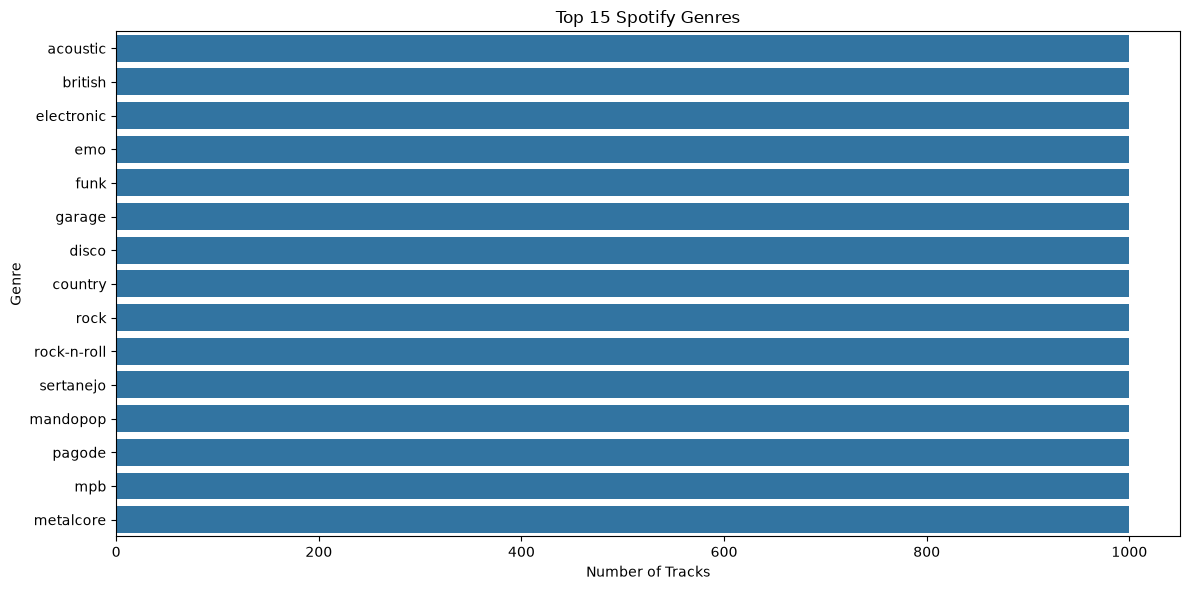

In [18]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Top 15 Spotify Genres")
plt.xlabel("Number of Tracks")
plt.ylabel("Genre")

plt.tight_layout()

plt.savefig(
    "../outputs/spotify/top_15_genres.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
top_genre = genre_counts.idxmax()
top_genre_count = genre_counts.max()

print("Most common genre:", top_genre)
print("Number of tracks:", top_genre_count)

Most common genre: acoustic
Number of tracks: 1000


In [20]:
artist_counts = (
    df_clean["artists"]
    .value_counts()
    .head(15)
)

print("Top 15 Artists by Number of Tracks:")
print(artist_counts)

Top 15 Artists by Number of Tracks:
artists
The Beatles              279
George Jones             260
Stevie Wonder            235
Linkin Park              224
Ella Fitzgerald          221
Prateek Kuhad            217
Feid                     201
Chuck Berry              190
Håkan Hellström          183
OneRepublic              181
The Beach Boys           173
my little airport        171
Charlie Brown Jr.        169
Elvis Presley            169
Red Hot Chili Peppers    158
Name: count, dtype: int64


In [21]:
top_tracks = (
    df_clean[
        ["track_name", "artists", "popularity"]
    ]
    .sort_values("popularity", ascending=False)
    .head(15)
)

print("Top 15 Most Popular Tracks:")
print(top_tracks.to_string(index=False))

Top 15 Most Popular Tracks:
                           track_name                    artists  popularity
            Unholy (feat. Kim Petras)       Sam Smith;Kim Petras         100
            Unholy (feat. Kim Petras)       Sam Smith;Kim Petras         100
Quevedo: Bzrp Music Sessions, Vol. 52           Bizarrap;Quevedo          99
                      I'm Good (Blue)    David Guetta;Bebe Rexha          98
                      I'm Good (Blue)    David Guetta;Bebe Rexha          98
                           La Bachata              Manuel Turizo          98
                           La Bachata              Manuel Turizo          98
                      I'm Good (Blue)    David Guetta;Bebe Rexha          98
                           La Bachata              Manuel Turizo          98
                           La Bachata              Manuel Turizo          98
                      Me Porto Bonito Bad Bunny;Chencho Corleone          97
                      Me Porto Bonito Bad Bunny;

In [22]:
artist_popularity = (
    df_clean.groupby("artists")
    .agg(
        Track_Count=("track_name", "count"),
        Average_Popularity=("popularity", "mean")
    )
    .sort_values("Average_Popularity", ascending=False)
)

print("Top Artists by Average Popularity:")
print(artist_popularity.head(15))

Top Artists by Average Popularity:
                             Track_Count  Average_Popularity
artists                                                     
Sam Smith;Kim Petras                   2               100.0
Bizarrap;Quevedo                       1                99.0
Manuel Turizo                          4                98.0
Bad Bunny;Chencho Corleone             4                97.0
Bad Bunny;Bomba Estéreo                4                94.5
Joji                                   1                94.0
Beyoncé                                1                93.0
Harry Styles                           3                92.0
Rema;Selena Gomez                      1                92.0
Rauw Alejandro;Lyanno;Brray            2                91.0
Drake;21 Savage                        1                91.0
Luar La L                              4                90.5
The Weeknd;Gesaffelstein               1                90.0
Bad Bunny;Rauw Alejandro               3          

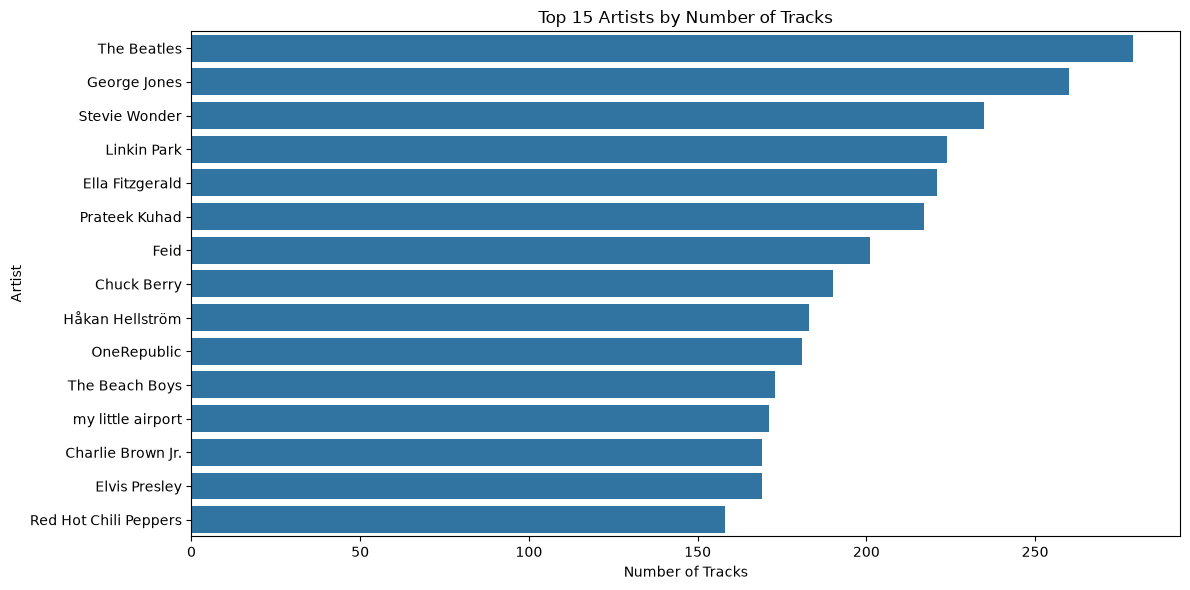

In [23]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=artist_counts.values,
    y=artist_counts.index
)

plt.title("Top 15 Artists by Number of Tracks")
plt.xlabel("Number of Tracks")
plt.ylabel("Artist")

plt.tight_layout()

plt.savefig(
    "../outputs/spotify/top_15_artists.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
print("Popularity Statistics:")
print(df_clean["popularity"].describe().round(2))

Popularity Statistics:
count    113549.00
mean         33.32
std          22.28
min           0.00
25%          17.00
50%          35.00
75%          50.00
max         100.00
Name: popularity, dtype: float64


In [25]:
df_clean["Popularity_Group"] = pd.cut(
    df_clean["popularity"],
    bins=[-1, 25, 50, 75, 100],
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

print("Popularity Group Distribution:")
print(df_clean["Popularity_Group"].value_counts())

Popularity Group Distribution:
Popularity_Group
Low            44041
Medium-Low     41759
Medium-High    25337
High            2412
Name: count, dtype: int64


In [26]:
print("\nPopularity Group Percentage:")
print(
    (df_clean["Popularity_Group"]
     .value_counts(normalize=True) * 100)
    .round(2)
)


Popularity Group Percentage:
Popularity_Group
Low            38.79
Medium-Low     36.78
Medium-High    22.31
High            2.12
Name: proportion, dtype: float64


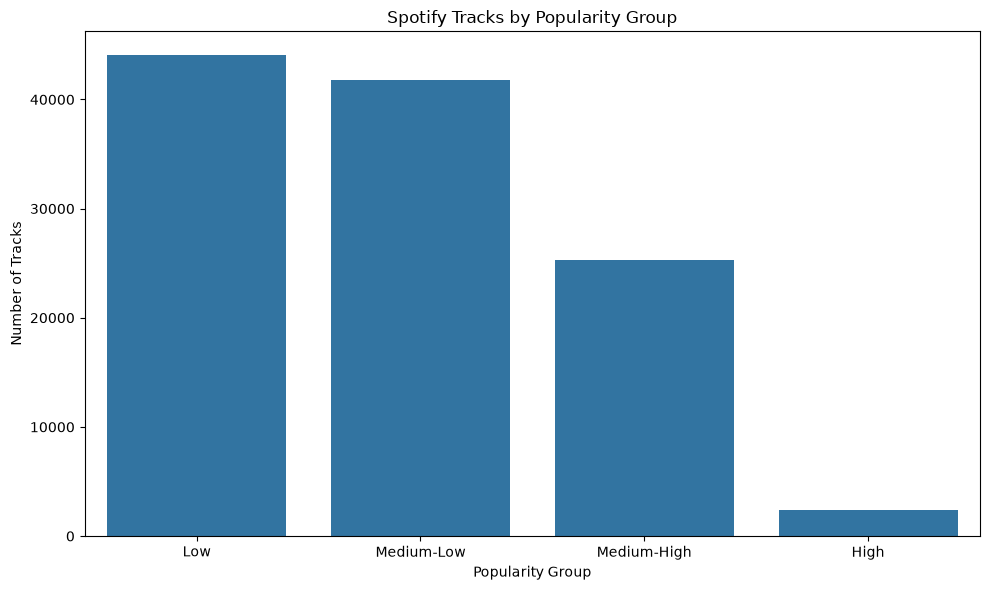

In [27]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_clean,
    x="Popularity_Group"
)

plt.title("Spotify Tracks by Popularity Group")
plt.xlabel("Popularity Group")
plt.ylabel("Number of Tracks")

plt.tight_layout()

plt.savefig(
    "../outputs/spotify/popularity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
popularity_features = (
    df_clean.groupby("Popularity_Group", observed=True)[
        ["danceability", "energy", "acousticness",
         "instrumentalness", "speechiness", "liveness", "valence"]
    ]
    .mean()
    .round(3)
)

print("Average Audio Features by Popularity Group:")
print(popularity_features)

Average Audio Features by Popularity Group:
                  danceability  energy  acousticness  instrumentalness  \
Popularity_Group                                                         
Low                      0.558   0.644         0.317             0.200   
Medium-Low               0.566   0.648         0.325             0.138   
Medium-High              0.578   0.627         0.304             0.119   
High                     0.633   0.677         0.197             0.029   

                  speechiness  liveness  valence  
Popularity_Group                                  
Low                     0.095     0.210    0.475  
Medium-Low              0.079     0.237    0.486  
Medium-High             0.075     0.186    0.451  
High                    0.080     0.171    0.508  


In [29]:
audio_features = [
    "popularity",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

correlation_matrix = df_clean[audio_features].corr().round(2)

print("Audio Features Correlation Matrix:")
print(correlation_matrix)

Audio Features Correlation Matrix:
                  popularity  danceability  energy  loudness  speechiness  \
popularity              1.00          0.03   -0.00      0.05        -0.05   
danceability            0.03          1.00    0.13      0.26         0.11   
energy                 -0.00          0.13    1.00      0.76         0.14   
loudness                0.05          0.26    0.76      1.00         0.06   
speechiness            -0.05          0.11    0.14      0.06         1.00   
acousticness           -0.02         -0.17   -0.73     -0.59        -0.00   
instrumentalness       -0.09         -0.18   -0.18     -0.43        -0.09   
liveness               -0.01         -0.13    0.18      0.08         0.21   
valence                -0.04          0.48    0.26      0.28         0.04   
tempo                   0.01         -0.05    0.25      0.21         0.02   

                  acousticness  instrumentalness  liveness  valence  tempo  
popularity               -0.02          

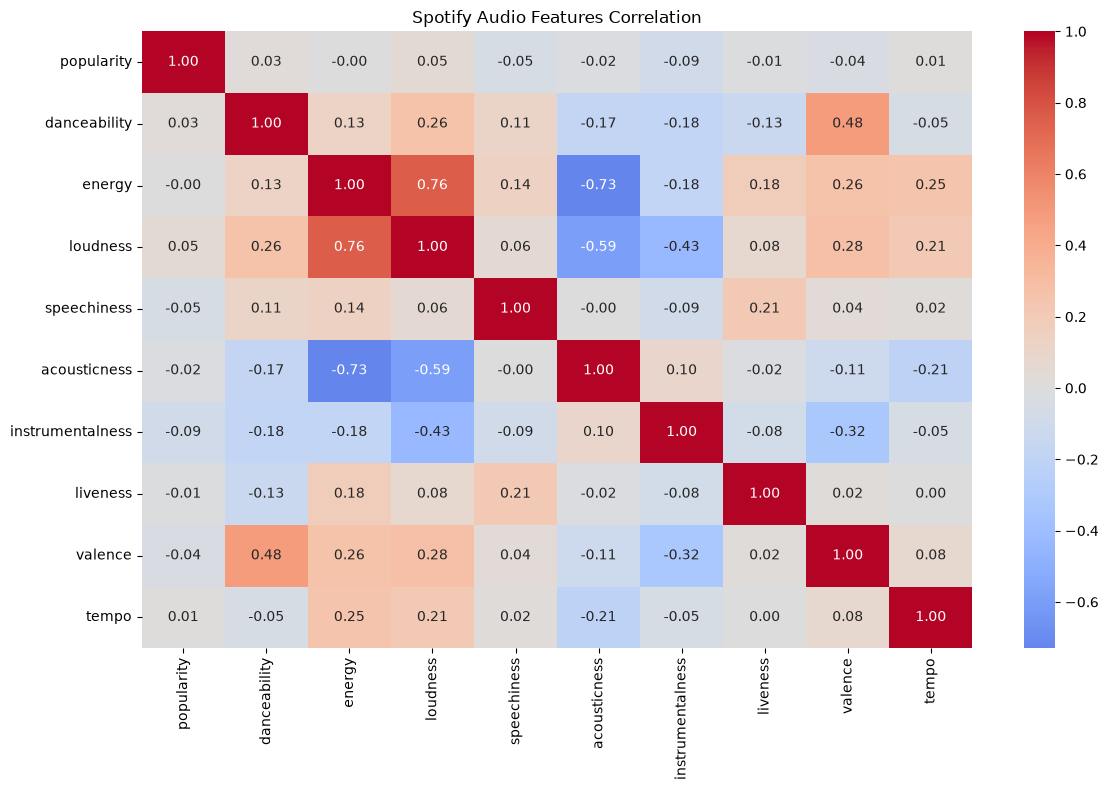

In [30]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Spotify Audio Features Correlation")

plt.tight_layout()

plt.savefig(
    "../outputs/spotify/audio_features_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
popularity_corr = (
    correlation_matrix["popularity"]
    .drop("popularity")
    .sort_values(ascending=False)
)

print("Correlation with Popularity:")
print(popularity_corr)

Correlation with Popularity:
loudness            0.05
danceability        0.03
tempo               0.01
energy             -0.00
liveness           -0.01
acousticness       -0.02
valence            -0.04
speechiness        -0.05
instrumentalness   -0.09
Name: popularity, dtype: float64


In [32]:
print("Danceability vs Popularity Correlation:",
      df_clean["danceability"].corr(df_clean["popularity"]).round(3))

print("Energy vs Popularity Correlation:",
      df_clean["energy"].corr(df_clean["popularity"]).round(3))

print("Valence vs Popularity Correlation:",
      df_clean["valence"].corr(df_clean["popularity"]).round(3))

Danceability vs Popularity Correlation: 0.034
Energy vs Popularity Correlation: -0.002
Valence vs Popularity Correlation: -0.041


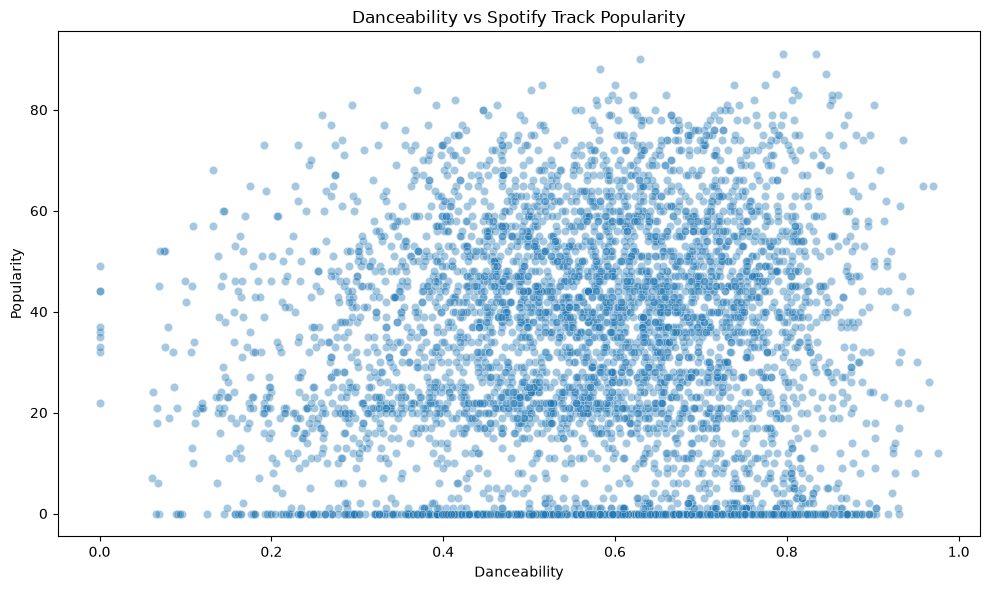

In [33]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean.sample(min(5000, len(df_clean)), random_state=42),
    x="danceability",
    y="popularity",
    alpha=0.4
)

plt.title("Danceability vs Spotify Track Popularity")
plt.xlabel("Danceability")
plt.ylabel("Popularity")

plt.tight_layout()
plt.savefig("../outputs/spotify/danceability_vs_popularity.png",
            dpi=300, bbox_inches="tight")
plt.show()

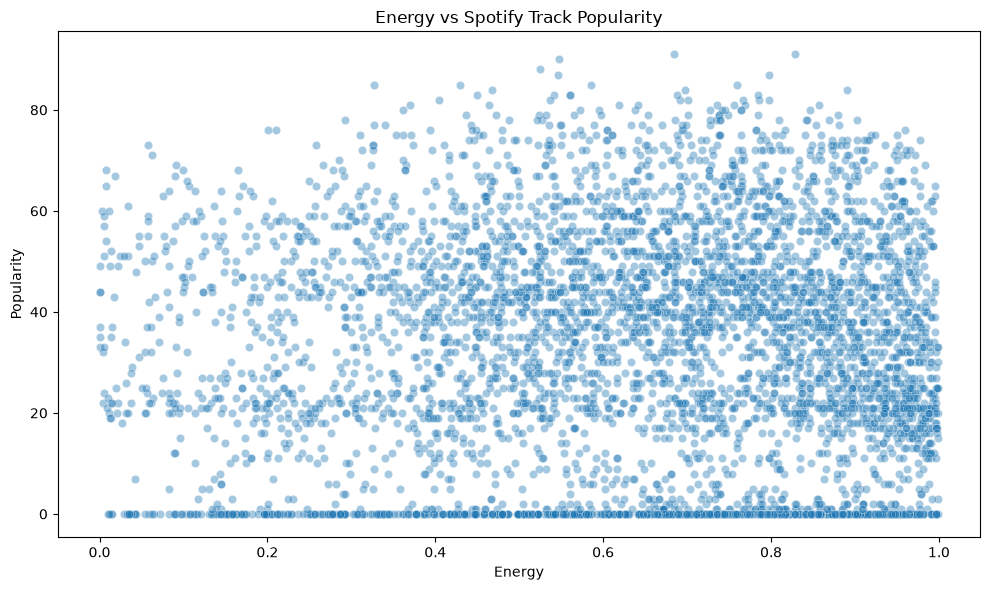

In [34]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean.sample(min(5000, len(df_clean)), random_state=42),
    x="energy",
    y="popularity",
    alpha=0.4
)

plt.title("Energy vs Spotify Track Popularity")
plt.xlabel("Energy")
plt.ylabel("Popularity")

plt.tight_layout()
plt.savefig("../outputs/spotify/energy_vs_popularity.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [35]:
genre_audio_analysis = df_clean.groupby("track_genre").agg(
    Average_Popularity=("popularity", "mean"),
    Average_Danceability=("danceability", "mean"),
    Average_Energy=("energy", "mean"),
    Average_Acousticness=("acousticness", "mean"),
    Average_Valence=("valence", "mean")
).round(3)

genre_audio_analysis = genre_audio_analysis.sort_values(
    by="Average_Popularity", ascending=False
)

print("Top 15 Genres by Average Popularity:")
display(genre_audio_analysis.head(15))

Top 15 Genres by Average Popularity:


,Average_Popularity,Average_Danceability,Average_Energy,Average_Acousticness,Average_Valence
track_genre,,,,,
pop-film,59.280,0.597,0.604,0.441,0.529
k-pop,56.964,0.648,0.676,0.292,0.557
chill,53.705,0.664,0.426,0.535,0.404
sad,52.379,0.692,0.462,0.474,0.422
grunge,49.583,0.457,0.803,0.053,0.400
indian,49.529,0.592,0.567,0.485,0.463
anime,48.767,0.538,0.674,0.268,0.435
emo,48.128,0.599,0.670,0.195,0.441
pop,47.903,0.630,0.606,0.346,0.507


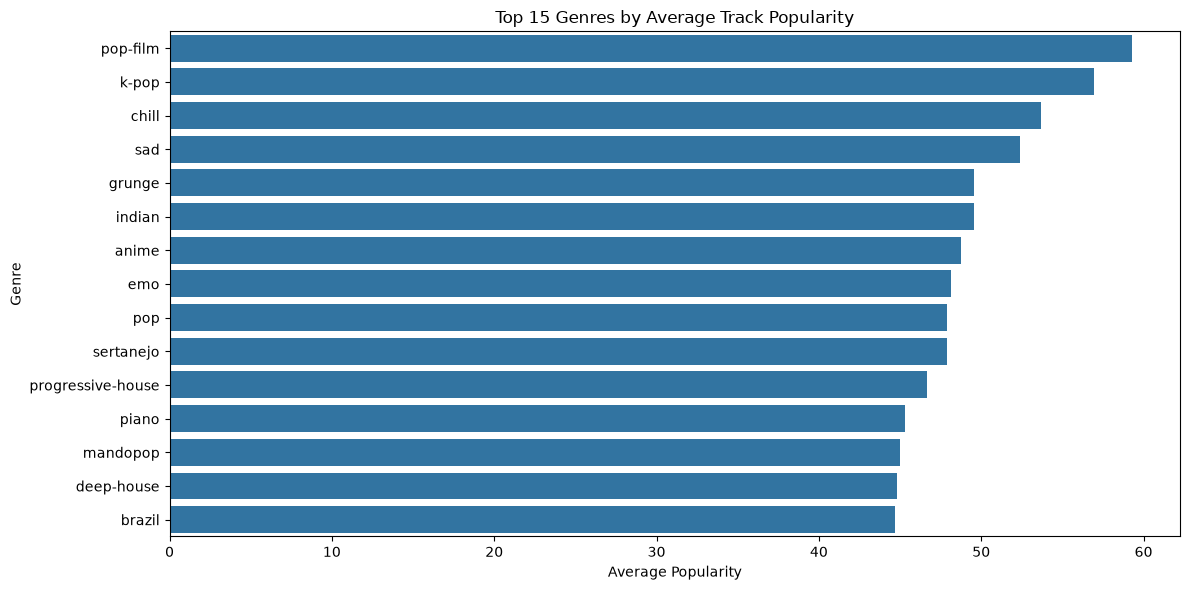

In [36]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=genre_audio_analysis.head(15).reset_index(),
    x="Average_Popularity",
    y="track_genre"
)

plt.title("Top 15 Genres by Average Track Popularity")
plt.xlabel("Average Popularity")
plt.ylabel("Genre")
plt.tight_layout()

plt.savefig(
    "../outputs/spotify/top_15_genres_by_popularity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
explicit_analysis = df_clean.groupby("explicit").agg(
    Track_Count=("track_name", "count"),
    Average_Popularity=("popularity", "mean"),
    Average_Danceability=("danceability", "mean"),
    Average_Energy=("energy", "mean"),
    Average_Valence=("valence", "mean"),
    Average_Speechiness=("speechiness", "mean")
).round(3)

print("Explicit vs Non-Explicit Track Analysis:")
display(explicit_analysis)

Explicit vs Non-Explicit Track Analysis:


,Track_Count,Average_Popularity,Average_Danceability,Average_Energy,Average_Valence,Average_Speechiness
explicit,,,,,,
False,103831,33.025,0.561,0.635,0.475,0.075
True,9718,36.525,0.636,0.721,0.471,0.191


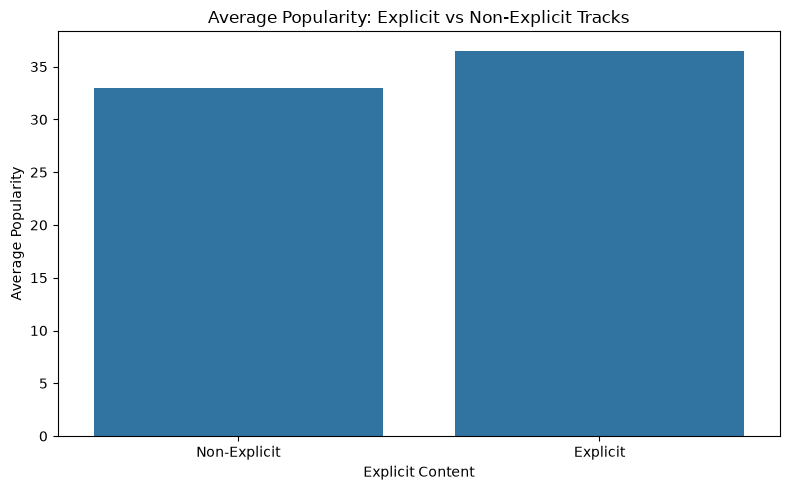

In [38]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="explicit",
    y="popularity",
    errorbar=None
)

plt.title("Average Popularity: Explicit vs Non-Explicit Tracks")
plt.xlabel("Explicit Content")
plt.ylabel("Average Popularity")
plt.xticks([0, 1], ["Non-Explicit", "Explicit"])
plt.tight_layout()

plt.savefig(
    "../outputs/spotify/explicit_vs_non_explicit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()